<center><h1>Inventory Analysis</h1></center>

In [1]:
# Load and inspect the cleaned inventory dataset

import pandas as pd
from pathlib import Path

file_path = Path("../data/processed/inventory_clean.csv")
inventory_df = pd.read_csv(file_path)

print("Dataset shape:", inventory_df.shape)
print("\nColumn names:")
print(inventory_df.columns.tolist())

print("\nFirst 5 rows:")
display(inventory_df.head())

print("\nMissing values:")
print(inventory_df.isnull().sum())

Dataset shape: (4800, 8)

Column names:
['Snapshot_Date', 'SKU', 'Current_Stock', 'On_Order', 'Lead_Time_Days', 'Safety_Stock', 'Reorder_Point', 'Inventory_Value']

First 5 rows:


,Snapshot_Date,SKU,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Reorder_Point,Inventory_Value
0,2024-01-01,SKU001,16,23,11,7,18,58420.96
1,2024-01-01,SKU002,29,12,4,5,10,163983.40
2,2024-01-01,SKU003,34,23,14,6,20,209060.22
3,2024-01-01,SKU004,34,4,7,5,12,42257.92
4,2024-01-01,SKU005,23,5,5,6,11,170945.89



Missing values:
Snapshot_Date      0
SKU                0
Current_Stock      0
On_Order           0
Lead_Time_Days     0
Safety_Stock       0
Reorder_Point      0
Inventory_Value    0
dtype: int64


In [3]:
# Identify products that may need replenishment

inventory_df["Snapshot_Date"] = pd.to_datetime(
    inventory_df["Snapshot_Date"]
)

latest_date = inventory_df["Snapshot_Date"].max()

latest_inventory = inventory_df[
    inventory_df["Snapshot_Date"] == latest_date
].copy()

latest_inventory["Reorder_Status"] = (
    latest_inventory["Current_Stock"]
    <= latest_inventory["Reorder_Point"]
).map({
    True: "Reorder Needed",
    False: "Stock Sufficient"
})

print("Latest snapshot date:", latest_date.date())
print("Number of SKUs:", latest_inventory["SKU"].nunique())
print("\nReorder status:")
display(latest_inventory["Reorder_Status"].value_counts())

print("\nProducts needing reorder:")
display(
    latest_inventory[
        latest_inventory["Reorder_Status"] == "Reorder Needed"
    ][[
        "SKU", "Current_Stock", "On_Order",
        "Lead_Time_Days", "Safety_Stock",
        "Reorder_Point", "Reorder_Status"
    ]].head(10)
)

Latest snapshot date: 2025-12-01
Number of SKUs: 200

Reorder status:


Reorder_Status
Stock Sufficient    136
Reorder Needed       64
Name: count, dtype: int64


Products needing reorder:


,SKU,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Reorder_Point,Reorder_Status
4606,SKU007,207,460,8,98,237,Reorder Needed
4608,SKU009,75,89,7,63,131,Reorder Needed
4611,SKU012,47,60,12,16,58,Reorder Needed
4614,SKU015,187,245,9,119,265,Reorder Needed
4616,SKU017,95,26,12,108,274,Reorder Needed
4620,SKU021,88,97,9,36,88,Reorder Needed
4621,SKU022,95,194,8,76,163,Reorder Needed
4622,SKU023,130,79,12,41,148,Reorder Needed
4627,SKU028,174,55,11,114,337,Reorder Needed
4628,SKU029,261,520,5,196,329,Reorder Needed


In [5]:
# Analyze stock coverage against reorder point and incoming orders

latest_inventory["Available_After_Order"] = (
    latest_inventory["Current_Stock"]
    + latest_inventory["On_Order"]
)

latest_inventory["Stock_Gap"] = (
    latest_inventory["Reorder_Point"]
    - latest_inventory["Available_After_Order"]
).clip(lower=0)

latest_inventory["Risk_Level"] = "Low Risk"

latest_inventory.loc[
    latest_inventory["Current_Stock"]
    <= latest_inventory["Reorder_Point"],
    "Risk_Level"
] = "Medium Risk"

latest_inventory.loc[
    latest_inventory["Available_After_Order"]
    < latest_inventory["Safety_Stock"],
    "Risk_Level"
] = "High Risk"

print("Risk level distribution:")
display(latest_inventory["Risk_Level"].value_counts())

print("\nHighest-risk products:")
display(
    latest_inventory.sort_values(
        ["Risk_Level", "Stock_Gap"],
        ascending=[True, False]
    )[[
        "SKU", "Current_Stock", "On_Order",
        "Available_After_Order", "Safety_Stock",
        "Reorder_Point", "Stock_Gap", "Risk_Level"
    ]].head(10)
)

Risk level distribution:


Risk_Level
Low Risk       136
Medium Risk     64
Name: count, dtype: int64


Highest-risk products:


,SKU,Current_Stock,On_Order,Available_After_Order,Safety_Stock,Reorder_Point,Stock_Gap,Risk_Level
4600,SKU001,771,147,918,159,289,0,Low Risk
4601,SKU002,526,29,555,94,149,0,Low Risk
4602,SKU003,349,12,361,88,123,0,Low Risk
4603,SKU004,259,254,513,98,196,0,Low Risk
4604,SKU005,471,291,762,129,245,0,Low Risk
4605,SKU006,359,485,844,129,340,0,Low Risk
4607,SKU008,325,155,480,91,161,0,Low Risk
4609,SKU010,83,70,153,22,60,0,Low Risk
4610,SKU011,753,269,1022,179,247,0,Low Risk
4612,SKU013,151,95,246,32,61,0,Low Risk


In [7]:
# Classify inventory risk after considering incoming stock

latest_inventory["Risk_Level"] = "Low Risk"

latest_inventory.loc[
    latest_inventory["Available_After_Order"]
    <= latest_inventory["Reorder_Point"],
    "Risk_Level"
] = "Medium Risk"

latest_inventory.loc[
    latest_inventory["Available_After_Order"]
    < latest_inventory["Safety_Stock"],
    "Risk_Level"
] = "High Risk"

risk_order = {
    "High Risk": 0,
    "Medium Risk": 1,
    "Low Risk": 2
}

print("Corrected risk distribution:")
display(
    latest_inventory["Risk_Level"]
    .value_counts()
    .reindex(["High Risk", "Medium Risk", "Low Risk"], fill_value=0)
)

print("\nHighest-risk products:")
display(
    latest_inventory.assign(
        Risk_Sort=latest_inventory["Risk_Level"].map(risk_order)
    ).sort_values(
        ["Risk_Sort", "Stock_Gap"],
        ascending=[True, False]
    )[[
        "SKU", "Current_Stock", "On_Order",
        "Available_After_Order", "Safety_Stock",
        "Reorder_Point", "Stock_Gap", "Risk_Level"
    ]].head(10)
)

Corrected risk distribution:


Risk_Level
High Risk        0
Medium Risk     13
Low Risk       187
Name: count, dtype: int64


Highest-risk products:


,SKU,Current_Stock,On_Order,Available_After_Order,Safety_Stock,Reorder_Point,Stock_Gap,Risk_Level
4779,SKU180,533,47,580,189,740,160,Medium Risk
4616,SKU017,95,26,121,108,274,153,Medium Risk
4674,SKU075,593,181,774,322,921,147,Medium Risk
4627,SKU028,174,55,229,114,337,108,Medium Risk
4785,SKU186,178,137,315,168,419,104,Medium Risk
4764,SKU165,123,22,145,66,217,72,Medium Risk
4774,SKU175,141,13,154,58,216,62,Medium Risk
4680,SKU081,178,16,194,73,242,48,Medium Risk
4697,SKU098,110,169,279,56,302,23,Medium Risk
4651,SKU052,36,0,36,29,43,7,Medium Risk


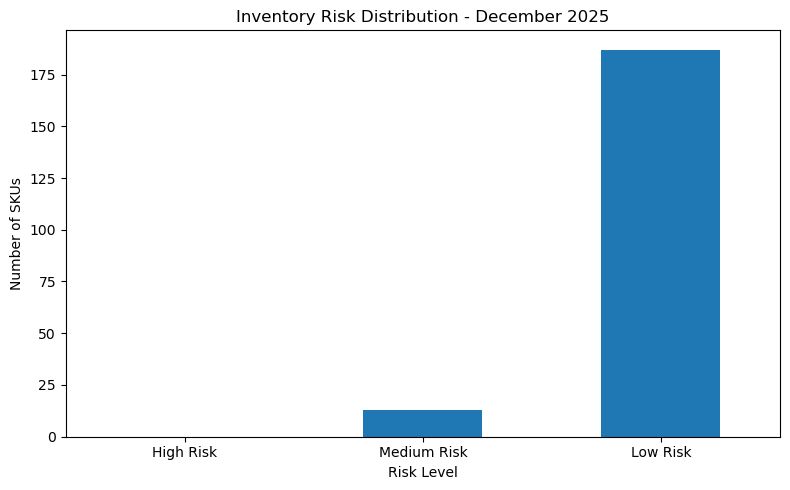

In [9]:
# Visualize inventory risk and stock status

import matplotlib.pyplot as plt

risk_counts = (
    latest_inventory["Risk_Level"]
    .value_counts()
    .reindex(["High Risk", "Medium Risk", "Low Risk"], fill_value=0)
)

plt.figure(figsize=(8, 5))
risk_counts.plot(kind="bar")
plt.title("Inventory Risk Distribution - December 2025")
plt.xlabel("Risk Level")
plt.ylabel("Number of SKUs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Save inventory analysis outputs

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

latest_inventory.to_csv(
    output_dir / "inventory_risk_analysis.csv",
    index=False
)

reorder_needed = latest_inventory[
    latest_inventory["Current_Stock"] <= latest_inventory["Reorder_Point"]
].copy()

reorder_needed.to_csv(
    output_dir / "inventory_reorder_recommendations.csv",
    index=False
)

print("Inventory risk analysis saved.")
print("File 1: inventory_risk_analysis.csv")
print("File 2: inventory_reorder_recommendations.csv")
print("Inventory rows saved:", len(latest_inventory))
print("Reorder recommendations:", len(reorder_needed))

Inventory risk analysis saved.
File 1: inventory_risk_analysis.csv
File 2: inventory_reorder_recommendations.csv
Inventory rows saved: 200
Reorder recommendations: 64


In [13]:
# Load the saved 30-day forecast for inventory planning

import pandas as pd
from pathlib import Path

forecast_path = Path("../data/processed/sales_forecast_next_30_days.csv")

forecast_df = pd.read_csv(forecast_path, parse_dates=["Date"])

display(forecast_df.head())
print("Forecast shape:", forecast_df.shape)
print("Forecast date range:", forecast_df["Date"].min(), "to", forecast_df["Date"].max())

,Date,Forecasted_Units_Sold,Lower_Bound,Upper_Bound
0,2026-01-01,604,530.754007,668.918893
1,2026-01-02,609,538.907462,673.867510
2,2026-01-03,766,699.820975,834.643591
3,2026-01-04,772,708.338184,840.203280
4,2026-01-05,607,530.669198,670.831495


Forecast shape: (30, 4)
Forecast date range: 2026-01-01 00:00:00 to 2026-01-30 00:00:00


In [15]:
# Load cleaned SKU-level sales data for inventory planning

from pathlib import Path
import pandas as pd

sales_path = Path("../data/processed/sales_clean.csv")
sales_df = pd.read_csv(sales_path, parse_dates=["Date"])

display(sales_df.head())

print("Sales data shape:", sales_df.shape)
print("Unique SKUs:", sales_df["SKU"].nunique())
print("Date range:", sales_df["Date"].min(), "to", sales_df["Date"].max())

,Date,SKU,Units_Sold,Revenue,Price,Promotion
0,2024-01-01,SKU001,5,18320.25,3664.05,0
1,2024-01-01,SKU002,15,57085.35,3805.69,0
2,2024-01-01,SKU003,5,40391.15,8078.23,0
3,2024-01-01,SKU004,5,34307.85,6861.57,0
4,2024-01-01,SKU005,12,113918.64,9493.22,0


Sales data shape: (36550, 6)
Unique SKUs: 50
Date range: 2024-01-01 00:00:00 to 2025-12-31 00:00:00


In [17]:
# Load cleaned inventory snapshots for SKU-level planning

from pathlib import Path
import pandas as pd

inventory_path = Path("../data/processed/inventory_clean.csv")
inventory_df = pd.read_csv(
    inventory_path,
    parse_dates=["Snapshot_Date"]
)

display(inventory_df.head())

print("Inventory shape:", inventory_df.shape)
print("Unique inventory SKUs:", inventory_df["SKU"].nunique())
print("Latest snapshot:", inventory_df["Snapshot_Date"].max())
print("Columns:", inventory_df.columns.tolist())

,Snapshot_Date,SKU,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Reorder_Point,Inventory_Value
0,2024-01-01,SKU001,16,23,11,7,18,58420.96
1,2024-01-01,SKU002,29,12,4,5,10,163983.40
2,2024-01-01,SKU003,34,23,14,6,20,209060.22
3,2024-01-01,SKU004,34,4,7,5,12,42257.92
4,2024-01-01,SKU005,23,5,5,6,11,170945.89


Inventory shape: (4800, 8)
Unique inventory SKUs: 200
Latest snapshot: 2025-12-01 00:00:00
Columns: ['Snapshot_Date', 'SKU', 'Current_Stock', 'On_Order', 'Lead_Time_Days', 'Safety_Stock', 'Reorder_Point', 'Inventory_Value']


In [25]:
# Calculate total forecast from the saved forecast file

from pathlib import Path
import pandas as pd

forecast_path = Path("../data/processed/sales_forecast_next_30_days.csv")
forecast_df = pd.read_csv(forecast_path)

total_forecast_30_days = forecast_df["Forecasted_Units_Sold"].sum()

print("Total 30-day forecast:", total_forecast_30_days)

Total 30-day forecast: 20111


In [29]:
# Allocate the 30-day total forecast using each SKU's recent sales share

cutoff_date = sales_df["Date"].max() - pd.Timedelta(days=89)

recent_sales = sales_df[
    (sales_df["Date"] >= cutoff_date) &
    (sales_df["Units_Sold"] > 0)
]

sku_demand = (
    recent_sales.groupby("SKU", as_index=False)["Units_Sold"]
    .sum()
    .rename(columns={"Units_Sold": "Recent_90_Day_Units"})
)

sku_demand["Demand_Share"] = (
    sku_demand["Recent_90_Day_Units"] /
    sku_demand["Recent_90_Day_Units"].sum()
)

total_forecast_30_days = forecast_df["Forecasted_Units_Sold"].sum()

sku_demand["Forecast_30_Day_Units"] = (
    sku_demand["Demand_Share"] * total_forecast_30_days
).round(0).astype(int)

sku_demand["Average_Daily_Demand"] = (
    sku_demand["Forecast_30_Day_Units"] / 30
)

display(
    sku_demand.sort_values(
        "Forecast_30_Day_Units",
        ascending=False
    ).head(10).round(2)
)

print("SKUs with sales:", sku_demand["SKU"].nunique())
print("Total 30-day forecast:", total_forecast_30_days)
print(
    "Allocated SKU forecast:",
    sku_demand["Forecast_30_Day_Units"].sum()
)

,SKU,Recent_90_Day_Units,Demand_Share,Forecast_30_Day_Units,Average_Daily_Demand
11,SKU012,1969,0.04,733,24.43
17,SKU018,1963,0.04,731,24.37
48,SKU049,1948,0.04,725,24.17
26,SKU027,1940,0.04,722,24.07
6,SKU007,1930,0.04,719,23.97
36,SKU037,1910,0.04,711,23.70
44,SKU045,1865,0.03,694,23.13
41,SKU042,1786,0.03,665,22.17
25,SKU026,1723,0.03,642,21.40
42,SKU043,1724,0.03,642,21.40


SKUs with sales: 50
Total 30-day forecast: 20111
Allocated SKU forecast: 20110


In [31]:
# Merge SKU demand estimates with the latest inventory snapshot

latest_inventory = (
    inventory_df
    .sort_values("Snapshot_Date")
    .drop_duplicates(subset="SKU", keep="last")
)

inventory_planning = latest_inventory.merge(
    sku_demand,
    on="SKU",
    how="left"
)

inventory_planning["Demand_Data_Available"] = (
    inventory_planning["Recent_90_Day_Units"].notna()
)

display(
    inventory_planning[
        [
            "SKU",
            "Snapshot_Date",
            "Current_Stock",
            "On_Order",
            "Lead_Time_Days",
            "Safety_Stock",
            "Recent_90_Day_Units",
            "Forecast_30_Day_Units",
            "Demand_Data_Available"
        ]
    ].head(10)
)

print("Latest inventory SKUs:", len(latest_inventory))
print(
    "SKUs with demand data:",
    inventory_planning["Demand_Data_Available"].sum()
)
print(
    "SKUs without matching sales data:",
    (~inventory_planning["Demand_Data_Available"]).sum()
)

,SKU,Snapshot_Date,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Recent_90_Day_Units,Forecast_30_Day_Units,Demand_Data_Available
0,SKU136,2025-12-01,74,152,10,35,NaN,NaN,False
1,SKU129,2025-12-01,81,40,3,23,NaN,NaN,False
2,SKU130,2025-12-01,692,322,6,135,NaN,NaN,False
3,SKU131,2025-12-01,95,135,9,39,NaN,NaN,False
4,SKU132,2025-12-01,184,196,14,71,NaN,NaN,False
5,SKU133,2025-12-01,1024,1089,14,271,NaN,NaN,False
6,SKU128,2025-12-01,428,150,13,130,NaN,NaN,False
7,SKU134,2025-12-01,191,180,11,43,NaN,NaN,False
8,SKU135,2025-12-01,223,288,10,86,NaN,NaN,False
9,SKU137,2025-12-01,468,437,12,202,NaN,NaN,False


Latest inventory SKUs: 200
SKUs with demand data: 50
SKUs without matching sales data: 150


In [33]:
# Calculate reorder recommendations for SKUs with matching sales data

import numpy as np

inventory_planning["Reorder_Target"] = np.nan
inventory_planning["Available_Inventory"] = (
    inventory_planning["Current_Stock"] +
    inventory_planning["On_Order"]
)
inventory_planning["Recommended_Order_Qty"] = np.nan
inventory_planning["Reorder_Needed"] = False

matched = inventory_planning["Demand_Data_Available"]

inventory_planning.loc[matched, "Reorder_Target"] = np.ceil(
    inventory_planning.loc[matched, "Average_Daily_Demand"] *
    inventory_planning.loc[matched, "Lead_Time_Days"] +
    inventory_planning.loc[matched, "Safety_Stock"]
)

inventory_planning.loc[matched, "Recommended_Order_Qty"] = np.maximum(
    inventory_planning.loc[matched, "Reorder_Target"] -
    inventory_planning.loc[matched, "Available_Inventory"],
    0
)

inventory_planning.loc[matched, "Reorder_Needed"] = (
    inventory_planning.loc[matched, "Recommended_Order_Qty"] > 0
)

recommendations = inventory_planning.loc[
    matched,
    [
        "SKU",
        "Current_Stock",
        "On_Order",
        "Lead_Time_Days",
        "Safety_Stock",
        "Average_Daily_Demand",
        "Available_Inventory",
        "Reorder_Target",
        "Recommended_Order_Qty",
        "Reorder_Needed"
    ]
].sort_values("Recommended_Order_Qty", ascending=False)

display(recommendations.head(15).round(2))

print("SKUs evaluated:", len(recommendations))
print("SKUs needing reorder:", int(recommendations["Reorder_Needed"].sum()))
print("Total recommended units:", int(recommendations["Recommended_Order_Qty"].sum()))

,SKU,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Average_Daily_Demand,Available_Inventory,Reorder_Target,Recommended_Order_Qty,Reorder_Needed
138,SKU012,47,60,12,16,24.43,107,310.0,203.0,True
143,SKU017,95,26,12,108,13.90,121,275.0,154.0,True
107,SKU031,93,40,13,28,17.83,133,260.0,127.0,True
136,SKU010,83,70,13,22,16.13,153,232.0,79.0,True
116,SKU040,67,29,9,36,14.27,96,165.0,69.0,True
124,SKU023,130,79,12,41,14.37,209,214.0,5.0,True
101,SKU025,1124,61,14,121,2.47,1185,156.0,0.0,False
139,SKU013,151,95,4,32,13.13,246,85.0,0.0,False
131,SKU005,471,291,6,129,16.77,762,230.0,0.0,False
132,SKU006,359,485,13,129,6.13,844,209.0,0.0,False


SKUs evaluated: 50
SKUs needing reorder: 6
Total recommended units: 637


In [35]:
# Save forecast-based inventory reorder recommendations

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "inventory_forecast_reorder_recommendations.csv"

recommendations.to_csv(output_file, index=False)

print("Recommendations saved successfully:", output_file.resolve())
print("Total SKU records saved:", len(recommendations))
print("SKUs needing reorder:", int(recommendations["Reorder_Needed"].sum()))
print(
    "Total recommended units:",
    int(recommendations["Recommended_Order_Qty"].sum())
)

Recommendations saved successfully: C:\Users\nikam\Desktop\RetailPulse\data\processed\inventory_forecast_reorder_recommendations.csv
Total SKU records saved: 50
SKUs needing reorder: 6
Total recommended units: 637


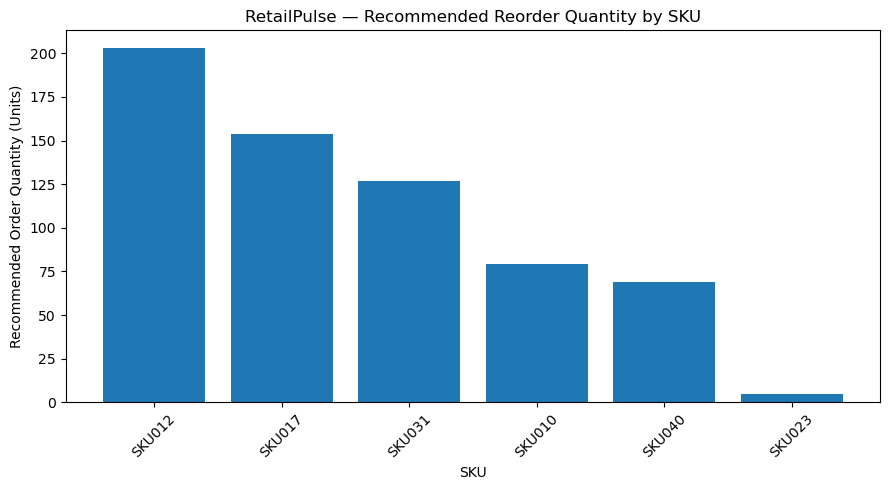

In [37]:
# Visualize the top SKU reorder recommendations

import matplotlib.pyplot as plt

top_reorders = (
    recommendations[recommendations["Recommended_Order_Qty"] > 0]
    .sort_values("Recommended_Order_Qty", ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    top_reorders["SKU"],
    top_reorders["Recommended_Order_Qty"]
)

plt.title("RetailPulse — Recommended Reorder Quantity by SKU")
plt.xlabel("SKU")
plt.ylabel("Recommended Order Quantity (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()